# Project 9: Optimizer Comparison Using a Neural Network
### Comparing Stochastic Gradient Descent (SGD) and Adam on the Iris Dataset

## 1. Aim
The aim of this project is to build a simple neural network for Iris flower classification and compare the SGD and Adam optimizers using the same training and testing data.

## 2. Objectives
- Load and explore the Iris classification dataset.
- Prepare the features and labels for a neural network.
- Train the same neural-network architecture using SGD and Adam.
- Compare test accuracy, test loss, training curves, and classification reports.
- Write a conclusion based on the results produced by the experiment.

## 3. Introduction
An optimizer updates a neural network's weights during training to reduce its loss. Different optimizers can learn at different speeds and may produce different results. In this experiment, I use the Iris dataset, which contains measurements of three types of iris flowers. I keep the data split and network architecture the same so the comparison focuses on the optimizer.

**Important:** The numerical results are generated when the notebook is run. I have not filled in made-up accuracy values.

## 4. Import Libraries
I start by importing the libraries needed for data handling, plotting, building the neural network, and evaluating classification performance. The random seed helps make the experiment more repeatable.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 5. Load and Explore the Iris Dataset
The Iris dataset has four numerical measurements for each flower and three target classes. I first inspect the dataset shape, class names, and a few rows to understand the data before training.

In [2]:
iris = load_iris()
X_raw = iris.data
y_raw = iris.target
class_names = iris.target_names

iris_df = pd.DataFrame(X_raw, columns=iris.feature_names)
iris_df["species"] = [class_names[i] for i in y_raw]

print("Dataset shape:", X_raw.shape)
print("Number of classes:", len(class_names))
print("Class names:", list(class_names))
display(iris_df.head())
print("\nSamples per class:")
display(iris_df["species"].value_counts().reindex(class_names))

Dataset shape: (150, 4)
Number of classes: 3
Class names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Samples per class:


,count
species,
setosa,50
versicolor,50
virginica,50


## 6. Split and Preprocess the Data
I reserve 20% of the data for testing and use the remaining 80% for training. Stratification keeps the class proportions similar in both sets. I fit the scaler only on the training features, then use it to transform both sets; this avoids letting test-set information influence preprocessing. The labels are converted to one-hot format for the softmax output layer.

In [3]:
X_train_raw, X_test_raw, y_train_int, y_test_int = train_test_split(
    X_raw,
    y_raw,
    test_size=0.20,
    random_state=SEED,
    stratify=y_raw
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

y_train = to_categorical(y_train_int, num_classes=3)
y_test = to_categorical(y_test_int, num_classes=3)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])

Training samples: 120
Testing samples: 30
Number of input features: 4


## 7. Define the Neural Network
Both optimizers use the same network: an input of four features, two hidden layers with ReLU activation, and a three-unit softmax output layer. Keeping the architecture fixed makes the comparison fairer.

In [4]:
def create_model():
    model = Sequential([
        Input(shape=(4,)),
        Dense(16, activation="relu"),
        Dense(8, activation="relu"),
        Dense(3, activation="softmax")
    ])
    return model

# Display the architecture
model_summary = create_model()
model_summary.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

## 8. Train the Model with SGD
SGD (Stochastic Gradient Descent) updates the weights using gradient information from mini-batches. I use a learning rate of 0.01 and train for 100 epochs. The validation split comes only from the training data.

In [5]:
tf.keras.utils.set_random_seed(SEED)
sgd_model = create_model()
sgd_model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

sgd_history = sgd_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.20,
    shuffle=True,
    verbose=0
)

print("SGD training completed.")
print("Final training accuracy:", round(sgd_history.history["accuracy"][-1], 4))
print("Final validation accuracy:", round(sgd_history.history["val_accuracy"][-1], 4))

SGD training completed.
Final training accuracy: 0.9375
Final validation accuracy: 0.9583


## 9. Train the Model with Adam
Adam adapts the update size for each parameter using estimates of gradient averages and squared gradients. I use the commonly used learning rate of 0.001. The training data, network architecture, batch size, number of epochs, and validation split remain the same as in the SGD experiment.

In [6]:
tf.keras.utils.set_random_seed(SEED)
adam_model = create_model()
adam_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

adam_history = adam_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.20,
    shuffle=True,
    verbose=0
)

print("Adam training completed.")
print("Final training accuracy:", round(adam_history.history["accuracy"][-1], 4))
print("Final validation accuracy:", round(adam_history.history["val_accuracy"][-1], 4))

Adam training completed.
Final training accuracy: 0.9688
Final validation accuracy: 1.0


## 10. Evaluate Both Models on the Test Set
I evaluate each model on the same held-out test set. Test accuracy shows the fraction of correctly classified flowers, while test loss measures the model's prediction error according to categorical cross-entropy.

In [7]:
sgd_test_loss, sgd_test_acc = sgd_model.evaluate(X_test, y_test, verbose=0)
adam_test_loss, adam_test_acc = adam_model.evaluate(X_test, y_test, verbose=0)

results = pd.DataFrame({
    "Optimizer": ["SGD", "Adam"],
    "Test Loss": [sgd_test_loss, adam_test_loss],
    "Test Accuracy (%)": [sgd_test_acc * 100, adam_test_acc * 100],
    "Final Training Accuracy (%)": [
        sgd_history.history["accuracy"][-1] * 100,
        adam_history.history["accuracy"][-1] * 100
    ],
    "Final Validation Accuracy (%)": [
        sgd_history.history["val_accuracy"][-1] * 100,
        adam_history.history["val_accuracy"][-1] * 100
    ]
})

display(results.round(4))

,Optimizer,Test Loss,Test Accuracy (%),Final Training Accuracy (%),Final Validation Accuracy (%)
0,SGD,0.2306,93.3333,93.750,95.8333
1,Adam,0.0916,96.6667,96.875,100.0000


## 11. Compare Training Accuracy
This graph shows how training accuracy changes over the epochs. A curve that rises earlier may indicate faster learning, but training accuracy alone does not establish which model generalizes better; I also check test performance.

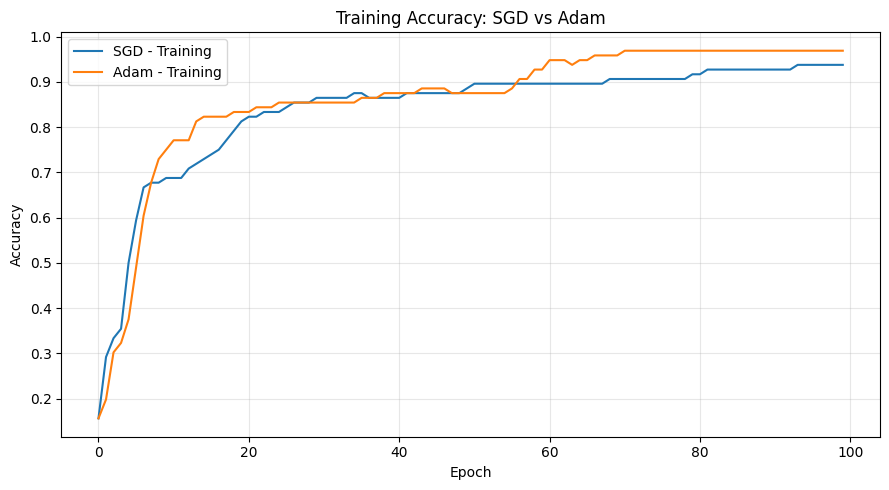

In [8]:
plt.figure(figsize=(9, 5))
plt.plot(sgd_history.history["accuracy"], label="SGD - Training")
plt.plot(adam_history.history["accuracy"], label="Adam - Training")
plt.title("Training Accuracy: SGD vs Adam")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Compare Training Loss
Loss indicates how far the model's predictions are from the target labels under the chosen loss function. A decreasing curve generally indicates that the model is learning from the training data.

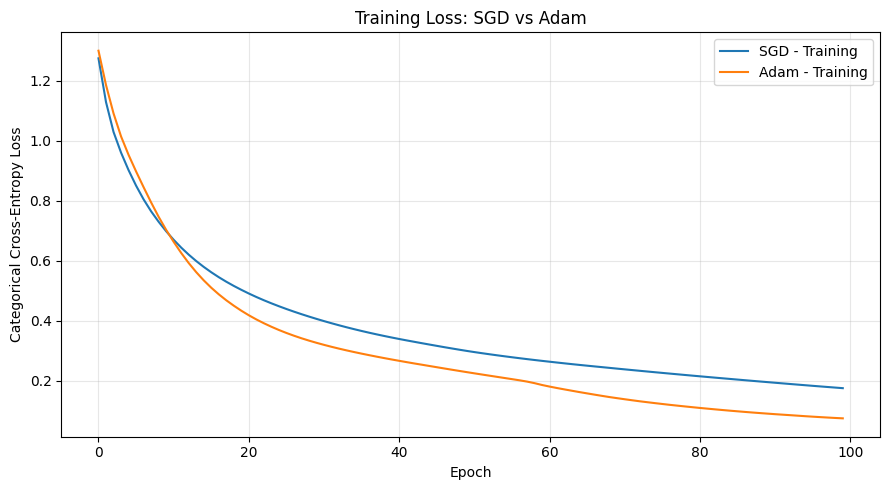

In [9]:
plt.figure(figsize=(9, 5))
plt.plot(sgd_history.history["loss"], label="SGD - Training")
plt.plot(adam_history.history["loss"], label="Adam - Training")
plt.title("Training Loss: SGD vs Adam")
plt.xlabel("Epoch")
plt.ylabel("Categorical Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Compare Validation Accuracy
Validation accuracy gives an additional view of performance on data not used for gradient updates during each epoch. Small datasets can show some variation, so I interpret this graph together with the final test metrics.

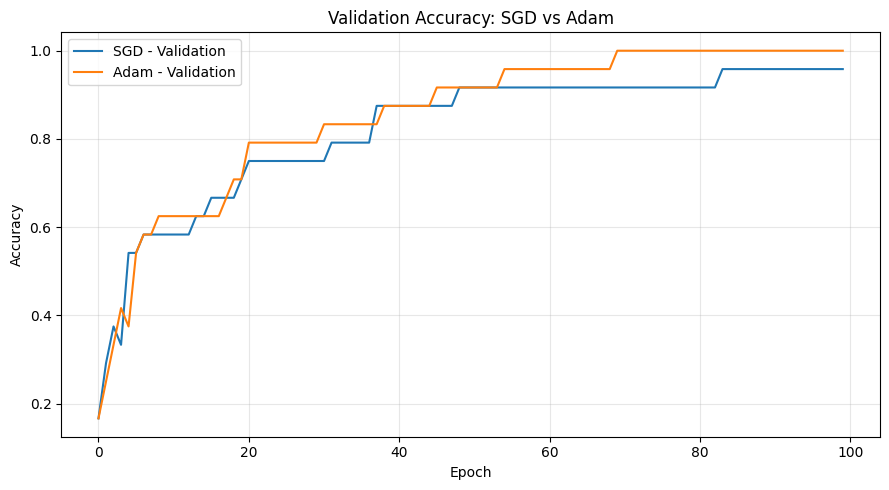

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(sgd_history.history["val_accuracy"], label="SGD - Validation")
plt.plot(adam_history.history["val_accuracy"], label="Adam - Validation")
plt.title("Validation Accuracy: SGD vs Adam")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 14. Classification Reports
The classification report shows precision, recall, and F1-score for each flower class. These measures help check whether a model performs consistently across all three species instead of relying only on overall accuracy.

In [11]:
sgd_pred = np.argmax(sgd_model.predict(X_test, verbose=0), axis=1)
adam_pred = np.argmax(adam_model.predict(X_test, verbose=0), axis=1)

print("SGD Classification Report")
print(classification_report(
    y_test_int, sgd_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

print("Adam Classification Report")
print(classification_report(
    y_test_int, adam_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

SGD Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.80      0.89        10
   virginica       0.83      1.00      0.91        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Adam Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## 15. Confusion Matrices
A confusion matrix compares the true species with the predicted species. Correct predictions appear on the diagonal; off-diagonal values indicate misclassifications.

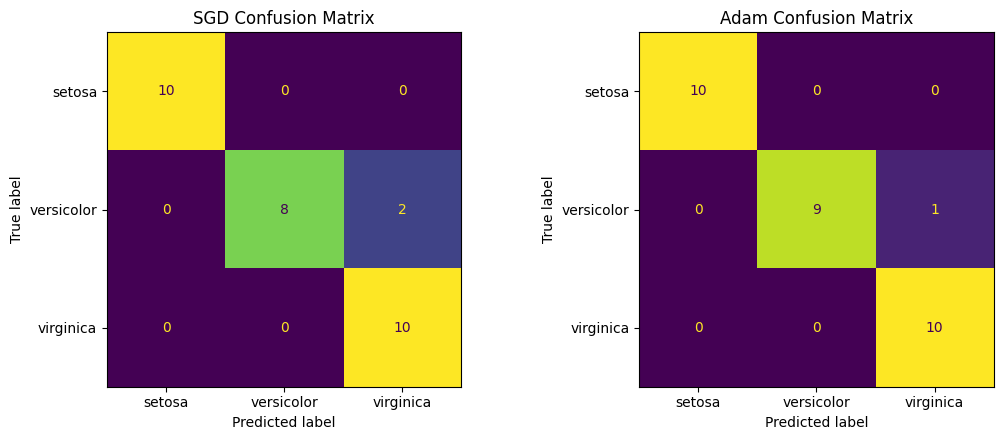

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test_int, sgd_pred, labels=[0, 1, 2]),
    display_labels=class_names
).plot(ax=axes[0], colorbar=False)
axes[0].set_title("SGD Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix(y_test_int, adam_pred, labels=[0, 1, 2]),
    display_labels=class_names
).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Adam Confusion Matrix")

plt.tight_layout()
plt.show()

## 16. Result Interpretation
The next cell identifies the optimizer with the higher test accuracy in this run. If both optimizers achieve the same accuracy, it reports a tie on that metric. This avoids assuming in advance that one optimizer must win.

In [13]:
if np.isclose(sgd_test_acc, adam_test_acc):
    accuracy_winner = "Both optimizers achieved the same test accuracy."
elif adam_test_acc > sgd_test_acc:
    accuracy_winner = "Adam achieved the higher test accuracy."
else:
    accuracy_winner = "SGD achieved the higher test accuracy."

if np.isclose(sgd_test_loss, adam_test_loss):
    loss_winner = "Both optimizers achieved the same test loss."
elif adam_test_loss < sgd_test_loss:
    loss_winner = "Adam achieved the lower test loss."
else:
    loss_winner = "SGD achieved the lower test loss."

print(accuracy_winner)
print(loss_winner)
print(f"SGD  -> Test accuracy: {sgd_test_acc * 100:.2f}%, Test loss: {sgd_test_loss:.4f}")
print(f"Adam -> Test accuracy: {adam_test_acc * 100:.2f}%, Test loss: {adam_test_loss:.4f}")

Adam achieved the higher test accuracy.
Adam achieved the lower test loss.
SGD  -> Test accuracy: 93.33%, Test loss: 0.2306
Adam -> Test accuracy: 96.67%, Test loss: 0.0916


## 17. Discussion
In this experiment, SGD and Adam were trained on the same Iris training set with the same neural-network architecture. Adam adapts parameter updates and often reaches a useful solution in fewer epochs, while SGD uses a simpler update rule and can work well with appropriate learning-rate tuning. However, the optimizer that performs best must be determined from the actual results rather than assumed.

The Iris dataset is small and relatively easy to classify, so both optimizers may achieve similar test accuracy. Differences in loss or training curves can still show differences in how they learn.

## 18. Conclusion
I built and evaluated a neural network for classifying Iris flowers using SGD and Adam. I compared their training accuracy, training loss, validation accuracy, test loss, test accuracy, classification reports, and confusion matrices. The results show how optimizer choice can affect the training process and final predictions. Based on the printed results, I can identify which optimizer performed better for this run; the conclusion should be based on the values produced when this notebook is executed.

